In [1]:
'hi'

'hi'

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv(r"C:\Users\DELL\Downloads\Loan-Approval-Prediction (1).csv")

In [4]:
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


## random forest

In [5]:
df.drop("Loan_ID",axis=1,inplace=True)

In [6]:
df

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...
609,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [7]:
df.isna().sum()

Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [8]:
df["Gender"]=df["Gender"].fillna(df["Gender"].mode())

In [9]:
col = ["Gender","Married","Dependents","Self_Employed"]

In [10]:
for c in col:
    df[c]=df[c].fillna(df[c].mode()[0])

In [11]:
df[col].isna().sum()

Gender           0
Married          0
Dependents       0
Self_Employed    0
dtype: int64

In [12]:
df["LoanAmount"].unique()
df["LoanAmount"] = df["LoanAmount"].fillna(df["LoanAmount"].mean())

In [13]:
df["LoanAmount"].isna().sum()

np.int64(0)

In [14]:
df["Loan_Amount_Term"].dtypes

dtype('float64')

In [15]:
df["Loan_Amount_Term"].mean()

np.float64(342.0)

In [16]:
df["Loan_Amount_Term"].mode()

0    360.0
Name: Loan_Amount_Term, dtype: float64

In [17]:
df["Loan_Amount_Term"] = df["Loan_Amount_Term"].fillna(df["Loan_Amount_Term"].mode()[0])

In [18]:
df["Credit_History"]=df["Credit_History"].fillna(df["Credit_History"].mode()[0])

In [19]:
df.isna().sum()

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

## IQR

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

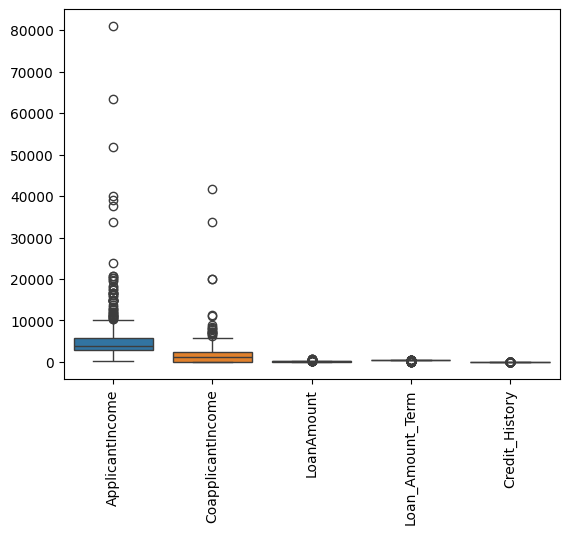

In [21]:
sns.boxplot(df)
plt.xticks(rotation=90)
plt.show()

In [22]:
df.dtypes

Gender                   str
Married                  str
Dependents               str
Education                str
Self_Employed            str
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
Loan_Status              str
dtype: object

In [23]:
## credit history nott taken because in credit.unique only 0 and 1 is there

In [24]:
cols = ["ApplicantIncome","CoapplicantIncome","LoanAmount","Loan_Amount_Term"]
cols

['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']

In [25]:
for i in cols:
    q1 = df[i].quantile(0.25)
    q3 = df[i].quantile(0.75)
    iqr = q3-q1
    lower = q1-(1.5*iqr)
    upper = q3+(1.5*iqr)
    df[i]=df[i].map(lambda x: lower if x<lower else upper if x>upper else x)


<Axes: >

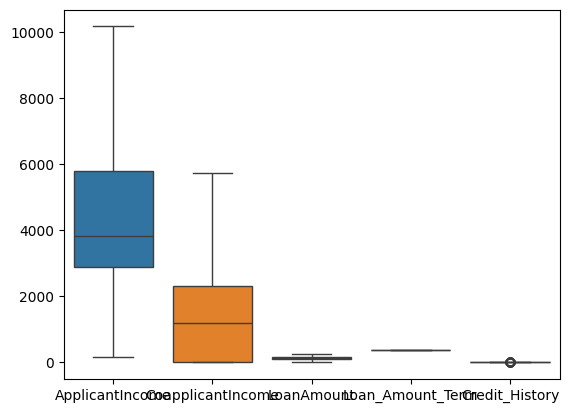

In [26]:
sns.boxplot(df)

## encoding

In [27]:
df.dtypes

Gender                   str
Married                  str
Dependents               str
Education                str
Self_Employed            str
ApplicantIncome      float64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
Loan_Status              str
dtype: object

In [28]:
df["Gender"].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [29]:
df["Married"].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

In [30]:
df["Dependents"].unique()

<StringArray>
['0', '1', '2', '3+']
Length: 4, dtype: str

In [31]:
df["Dependents"]=df["Dependents"].replace("3+",3)

In [32]:
df["Dependents"].unique()

array(['0', '1', '2', 3], dtype=object)

In [33]:
df["Dependents"] = df["Dependents"].astype(int)

In [34]:
df["Dependents"].unique()

array([0, 1, 2, 3])

In [35]:
from sklearn.preprocessing import OrdinalEncoder

In [36]:
ord = OrdinalEncoder()

In [37]:
ary = ord.fit_transform(df[["Education"]])

In [38]:
df["Education"] = ary

In [39]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,0.0,No,5849.0,0.0,146.412162,360.0,1.0,Urban,Y
1,Male,Yes,1,0.0,No,4583.0,1508.0,128.000000,360.0,1.0,Rural,N
2,Male,Yes,0,0.0,Yes,3000.0,0.0,66.000000,360.0,1.0,Urban,Y
3,Male,Yes,0,1.0,No,2583.0,2358.0,120.000000,360.0,1.0,Urban,Y
4,Male,No,0,0.0,No,6000.0,0.0,141.000000,360.0,1.0,Urban,Y


In [40]:
df["Self_Employed"].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

In [41]:
df["Property_Area"].unique()

<StringArray>
['Urban', 'Rural', 'Semiurban']
Length: 3, dtype: str

In [42]:
df["Loan_Status"].unique()

<StringArray>
['Y', 'N']
Length: 2, dtype: str

In [43]:
from sklearn.preprocessing import LabelEncoder

In [44]:
lrd = LabelEncoder()

In [45]:
df["Loan_Status"] = lrd.fit_transform(df["Loan_Status"])

In [46]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,0.0,No,5849.0,0.0,146.412162,360.0,1.0,Urban,1
1,Male,Yes,1,0.0,No,4583.0,1508.0,128.000000,360.0,1.0,Rural,0
2,Male,Yes,0,0.0,Yes,3000.0,0.0,66.000000,360.0,1.0,Urban,1
3,Male,Yes,0,1.0,No,2583.0,2358.0,120.000000,360.0,1.0,Urban,1
4,Male,No,0,0.0,No,6000.0,0.0,141.000000,360.0,1.0,Urban,1


In [47]:
df = pd.get_dummies(df,dtype=int)

In [48]:
df

,Dependents,Education,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Gender_Female,Gender_Male,Married_No,Married_Yes,Self_Employed_No,Self_Employed_Yes,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,0,0.0,5849.0,0.0,146.412162,360.0,1.0,1,0,1,1,0,1,0,0,0,1
1,1,0.0,4583.0,1508.0,128.000000,360.0,1.0,0,0,1,0,1,1,0,1,0,0
2,0,0.0,3000.0,0.0,66.000000,360.0,1.0,1,0,1,0,1,0,1,0,0,1
3,0,1.0,2583.0,2358.0,120.000000,360.0,1.0,1,0,1,0,1,1,0,0,0,1
4,0,0.0,6000.0,0.0,141.000000,360.0,1.0,1,0,1,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,0,0.0,2900.0,0.0,71.000000,360.0,1.0,1,1,0,1,0,1,0,1,0,0
610,3,0.0,4106.0,0.0,40.000000,360.0,1.0,1,0,1,0,1,1,0,1,0,0
611,1,0.0,8072.0,240.0,253.000000,360.0,1.0,1,0,1,0,1,1,0,0,0,1
612,2,0.0,7583.0,0.0,187.000000,360.0,1.0,1,0,1,0,1,1,0,0,0,1


In [49]:
df.shape

(614, 17)

In [50]:
"hi"

'hi'